In [21]:
# CELL 1: install
!pip install -q sentence-transformers sentencepiece

In [22]:
# CELL 2: imports + config
import os, re, glob, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.models as tvm, torchvision.transforms as T
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score
warnings.filterwarnings("ignore")

CFG = dict(
    mediaeval_dir="/kaggle/input/datasets/sashanknekkanti07/mediaeval",
    weibo_dir="/kaggle/input/datasets/sashanknekkanti07/weibo-dataset",
    work_dir="/kaggle/working",
    seeds=[0, 1, 2],
    val_frac=0.15,
    target_acc=0.85,
    # (SBERT, DeBERTa) per language
    models={
        "en": ("sentence-transformers/all-mpnet-base-v2", "microsoft/deberta-v3-base"),
        "zh": ("sentence-transformers/paraphrase-multilingual-mpnet-base-v2", "microsoft/mdeberta-v3-base"),
    },
)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
IMG_EXT = (".jpg", ".jpeg", ".png", ".gif", ".bmp", ".webp")
ALL_RESULTS = {}   # filled by cells 7 and 8, read by cell 9
print("Device:", DEV)

Device: cuda


In [23]:
# CELL 3: helpers
def show_tree(root, depth=2):
    print(f"\n[tree] {root}")
    base = root.rstrip("/").count("/")
    for dp, dn, fn in os.walk(root):
        d = dp.count("/") - base
        if d > depth:
            continue
        print("  " * d + os.path.basename(dp) + f"/  ({len(fn)} files)")
        for f in fn[:3]:
            print("  " * (d + 1) + f)

def build_image_index(root):
    idx = {}
    for dp, _, fs in os.walk(root):
        for f in fs:
            if f.lower().endswith(IMG_EXT):
                idx.setdefault(os.path.splitext(f)[0].lower(), os.path.join(dp, f))
    print(f"[images] indexed {len(idx)} images under {root}")
    return idx

def find_image(ref, idx):
    for tok in re.split(r"[|,;\s]+", str(ref)):
        tok = tok.strip()
        if not tok or tok.lower() == "null":
            continue
        stem = os.path.splitext(os.path.basename(tok))[0].lower()
        if stem in idx:
            return idx[stem]
    return None

def clean_text(s):
    s = re.sub(r"http\S+|www\.\S+", " ", str(s))
    return re.sub(r"\s+", " ", s).strip()

def map_label(v):
    s = str(v).strip().lower()
    if s in ("fake", "humor", "humour", "rumor", "rumour", "1", "1.0"):
        return 1
    if s in ("real", "nonrumor", "non-rumor", "0", "0.0"):
        return 0
    return None

In [24]:
# CELL 4: dataset loaders
def read_table_any(f):
    for sep in ["\t", ","]:
        try:
            df = pd.read_csv(f, sep=sep, encoding="utf-8", on_bad_lines="skip",
                             engine="python", quoting=3 if sep == "\t" else 0)
            if df.shape[1] >= 3:
                return df
        except Exception:
            pass
    return None

def pick(cols, cands):
    low = {c.lower(): c for c in cols}
    for c in cands:
        if c.lower() in low:
            return low[c.lower()]
    return None

def load_mediaeval(root, idx):
    parts = []
    for f in glob.glob(root + "/**/*", recursive=True):
        if not f.lower().endswith((".txt", ".csv", ".tsv")) or os.path.getsize(f) < 1000:
            continue
        df = read_table_any(f)
        if df is None:
            continue
        tc = pick(df.columns, ["tweetText", "text", "content", "post_text"])
        lc = pick(df.columns, ["label", "labels"])
        ic = pick(df.columns, ["imageId(s)", "imageId", "image_id", "image", "images", "image_path"])
        if not (tc and lc and ic):
            continue
        rel = os.path.relpath(f, root).lower()
        if "testset" in rel or "/test" in rel:
            split = "test"
        elif "devset" in rel or "train" in rel:
            split = "train"
        else:
            split = "extra"          # unknown origin (e.g. tweets_dataset_no2.txt)
        d = pd.DataFrame({"text": df[tc], "label": df[lc], "image": df[ic]})
        d["split"], d["src"] = split, rel
        print(f"[table] {rel}: {len(d)} rows -> {split}")
        parts.append(d)
    if not parts:
        raise RuntimeError("No table with text/label/image columns found. Check the tree and edit load_mediaeval().")
    return pd.concat(parts, ignore_index=True)

def load_weibo(root, idx):
    rows = []
    for f in glob.glob(root + "/**/*.txt", recursive=True):
        b = os.path.basename(f).lower()
        if "rumor" not in b:
            continue
        label = 0 if ("nonrumor" in b or "non_rumor" in b or "non-rumor" in b) else 1
        split = "test" if "test" in b else "train"
        lines = open(f, encoding="utf-8", errors="ignore").read().split("\n")
        for i in range(0, len(lines) - 2, 3):      # 3 lines per post: meta / image urls / text
            rows.append(dict(text=lines[i + 2], image=lines[i + 1], label=label, split=split))
        print(f"[weibo] parsed {f}")
    if rows:
        return pd.DataFrame(rows)
    return load_mediaeval(root, idx)                # fallback: generic table

def prepare(name, root, loader, within_split=False):
    show_tree(root)
    idx = build_image_index(root)
    df = loader(root, idx)
    df["label"] = df["label"].map(map_label)
    df["text"] = df["text"].map(clean_text)
    df["img_path"] = df["image"].map(lambda r: find_image(r, idx))
    n0 = len(df)
    df = df.dropna(subset=["label", "img_path"])
    key = ["text", "img_path"] + (["split"] if within_split else [])
    df = df[df.text.str.len() > 0].drop_duplicates(subset=key).reset_index(drop=True)
    df["label"] = df["label"].astype(int)
    print(f"[{name}] kept {len(df)}/{n0} posts with text+image | fake ratio {df.label.mean():.3f}")
    if not {"train", "test"} <= set(df.split.unique()):
        print(f"[{name}] WARNING: no official train/test split found, using random stratified 80/20. "
              f"Random splits leak events and inflate accuracy.")
        _, te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=df.label, random_state=42)
        df["split"] = "train"
        df.loc[te, "split"] = "test"
    print(df.split.value_counts().to_dict())
    return df

In [25]:
# CELL 5: feature extractors
@torch.no_grad()
def enc_sbert(texts, name):
    from sentence_transformers import SentenceTransformer
    m = SentenceTransformer(name, device=DEV)
    out = m.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    del m; torch.cuda.empty_cache()
    return out.astype(np.float32)

@torch.no_grad()
def enc_deberta(texts, name, bs=32):
    from transformers import AutoTokenizer, AutoModel
    tok, m = AutoTokenizer.from_pretrained(name), AutoModel.from_pretrained(name).to(DEV).eval()
    out = []
    for i in tqdm(range(0, len(texts), bs), desc="DeBERTa"):
        b = tok(texts[i:i + bs], padding=True, truncation=True, max_length=128, return_tensors="pt").to(DEV)
        h = m(**b).last_hidden_state
        mk = b["attention_mask"].unsqueeze(-1).float()
        out.append(((h * mk).sum(1) / mk.sum(1)).cpu())
    del m; torch.cuda.empty_cache()
    return torch.cat(out).numpy().astype(np.float32)

class ImgDS(torch.utils.data.Dataset):
    def __init__(self, paths):
        self.p = paths
        self.t = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),
                            T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        try:
            im = Image.open(self.p[i]).convert("RGB")
        except Exception:
            im = Image.new("RGB", (224, 224))
        return self.t(im)

@torch.no_grad()
def enc_resnet(paths):
    m = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = nn.Identity()
    m = m.to(DEV).eval()
    dl = torch.utils.data.DataLoader(ImgDS(paths), batch_size=64, num_workers=2)
    out = [m(x.to(DEV)).cpu() for x in tqdm(dl, desc="ResNet-50")]
    del m; torch.cuda.empty_cache()
    return torch.cat(out).numpy().astype(np.float32)

def get_features(name, df, lang):
    p = os.path.join(CFG["work_dir"], f"feats_{name}.npz")
    if os.path.exists(p):
        z = np.load(p)
        if len(z["s"]) == len(df):
            print(f"[{name}] loaded cached features")
            return z["s"], z["d"], z["v"]
    sb, db = CFG["models"][lang]
    texts = df.text.tolist()
    s, d, v = enc_sbert(texts, sb), enc_deberta(texts, db), enc_resnet(df.img_path.tolist())
    np.savez(p, s=s, d=d, v=v)
    return s, d, v

In [26]:
# CELL 6: models + training
class MLP(nn.Module):
    def __init__(self, din, h=256, p=0.4):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(din, h), nn.GELU(), nn.Dropout(p), nn.Linear(h, 2))
    def forward(self, x):
        return self.net(x)

class AttnFusion(nn.Module):
    """Feature-level fusion: project both modalities to a shared space, self-attention over [text, image]."""
    def __init__(self, dt, dv, d=256, heads=4, p=0.4):
        super().__init__()
        self.pt = nn.Sequential(nn.Dropout(0.2), nn.Linear(dt, d))
        self.pv = nn.Sequential(nn.Dropout(0.2), nn.Linear(dv, d))
        self.att = nn.MultiheadAttention(d, heads, dropout=0.1, batch_first=True)
        self.ln = nn.LayerNorm(d)
        self.cls = nn.Sequential(nn.GELU(), nn.Dropout(p), nn.Linear(d, 2))
    def forward(self, xt, xv):
        z = torch.stack([self.pt(xt), self.pv(xv)], 1)
        a, _ = self.att(z, z, z)
        return self.cls(self.ln(z + a).mean(1))

def logits_of(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(*[x[i:i + 1024] for x in X]) for i in range(0, len(X[0]), 1024)])

def fit(model, Xtr, ytr, Xva, yva, epochs=80, patience=12, lr=1e-3, bs=128):
    model.to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    cnt = np.bincount(ytr.cpu().numpy(), minlength=2)
    w = torch.tensor(len(ytr) / (2 * np.maximum(cnt, 1)), dtype=torch.float32, device=DEV)
    best, best_state, bad = -1, None, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(ytr), device=DEV)
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            loss = F.cross_entropy(model(*[x[b] for x in Xtr]), ytr[b], weight=w, label_smoothing=0.05)
            opt.zero_grad(); loss.backward(); opt.step()
        f = f1_score(yva.cpu().numpy(), logits_of(model, Xva).argmax(1).cpu().numpy(), average="macro")
        if f > best:
            best, bad = f, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model

def calibrated_probs(model, Xva, yva, Xte):
    """Temperature scaling on the validation set so confidences are comparable across modalities."""
    lv, lt = logits_of(model, Xva), logits_of(model, Xte)
    best_T, best_nll = 1.0, 1e9
    for t in np.linspace(0.5, 4, 36):
        nll = F.cross_entropy(lv / t, yva).item()
        if nll < best_nll:
            best_T, best_nll = t, nll
    return F.softmax(lv / best_T, 1).cpu().numpy(), F.softmax(lt / best_T, 1).cpu().numpy()

In [27]:
# CELL 7: reliability-aware fusion + experiment runner
def softmax_np(a):
    e = np.exp(a - a.max())
    return e / e.sum()

def reliability_fuse(pv, pt, yv, tau, use_ds=True, use_sample=True):
    names = list(pv)
    a = np.array([f1_score(yv, pv[k].argmax(1), average="macro") for k in names])
    ds = softmax_np(a / tau) if use_ds else np.ones(len(names)) / len(names)
    W = []
    for k, d in zip(names, ds):
        ent = -(pt[k] * np.log(pt[k] + 1e-9)).sum(1) / np.log(2)
        W.append(d * ((1 - ent) + 1e-3 if use_sample else np.ones(len(ent))))
    W = np.stack(W, 1)
    W = W / W.sum(1, keepdims=True)
    return sum(W[:, i:i + 1] * pt[k] for i, k in enumerate(names)), ds

def best_tau(pv, yv):
    scores = {}
    for tau in [0.02, 0.05, 0.1, 0.2, 1.0]:
        p, _ = reliability_fuse(pv, pv, yv, tau)
        scores[tau] = accuracy_score(yv, p.argmax(1))
    return max(scores, key=scores.get)

def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", pos_label=1, zero_division=0)
    return dict(Acc=accuracy_score(y, p), Prec=pr, Rec=rc, F1=f1)

def run_dataset(name, df, lang):
    S, D, V = get_features(name, df, lang)
    y_all = df.label.values
    tr_all = np.where(df.split == "train")[0]
    te = np.where(df.split == "test")[0]
    results = {}
    def log(method, y, p):
        results.setdefault(method, []).append(metrics(y, p))

    for seed in CFG["seeds"]:
        torch.manual_seed(seed); np.random.seed(seed)
        tr, va = train_test_split(tr_all, test_size=CFG["val_frac"], stratify=y_all[tr_all], random_state=seed)

        def prep(A):
            mu, sd = A[tr].mean(0), A[tr].std(0) + 1e-6
            t = lambda ix: torch.tensor((A[ix] - mu) / sd, dtype=torch.float32, device=DEV)
            return t(tr), t(va), t(te)

        feats = {"S": prep(S), "D": prep(D), "V": prep(V)}
        feats["T"] = tuple(torch.cat([feats["S"][i], feats["D"][i]], 1) for i in range(3))
        yt = lambda ix: torch.tensor(y_all[ix], dtype=torch.long, device=DEV)
        ytr, yva = yt(tr), yt(va)
        yv_np, yte = y_all[va], y_all[te]

        experts = {}
        for key in ["T", "V", "S", "D"]:
            m = fit(MLP(feats[key][0].shape[1]), [feats[key][0]], ytr, [feats[key][1]], yva)
            experts[key] = calibrated_probs(m, [feats[key][1]], yva, [feats[key][2]])
        m = fit(AttnFusion(feats["T"][0].shape[1], feats["V"][0].shape[1]),
                [feats["T"][0], feats["V"][0]], ytr, [feats["T"][1], feats["V"][1]], yva)
        experts["F"] = calibrated_probs(m, [feats["T"][1], feats["V"][1]], yva, [feats["T"][2], feats["V"][2]])

        pv = {k: v[0] for k, v in experts.items()}
        pt = {k: v[1] for k, v in experts.items()}

        # unimodal baselines
        log("Text-only (SBERT+DeBERTa)", yte, pt["T"].argmax(1))
        log("Text-only (SBERT)", yte, pt["S"].argmax(1))
        log("Text-only (DeBERTa)", yte, pt["D"].argmax(1))
        log("Image-only (ResNet-50)", yte, pt["V"].argmax(1))
        # conventional multimodal fusion
        log("Feature-level attention fusion", yte, pt["F"].argmax(1))
        log("Decision-level soft voting (T+I)", yte, ((pt["T"] + pt["V"]) / 2).argmax(1))
        hard = (pt["T"].argmax(1) + pt["V"].argmax(1) + pt["F"].argmax(1) >= 2).astype(int)
        log("Decision-level hard voting (T, I, Attn)", yte, hard)
        # proposed + ablations
        sub = ["T", "V", "F"]
        pv3, pt3 = {k: pv[k] for k in sub}, {k: pt[k] for k in sub}
        tau = best_tau(pv3, yv_np)
        full, ds = reliability_fuse(pv3, pt3, yv_np, tau)
        log("Reliability-aware fusion (proposed)", yte, full.argmax(1))
        log("  ablation: w/o sample-level reliability", yte, reliability_fuse(pv3, pt3, yv_np, tau, True, False)[0].argmax(1))
        log("  ablation: w/o dataset-level reliability", yte, reliability_fuse(pv3, pt3, yv_np, tau, False, True)[0].argmax(1))
        p2 = reliability_fuse({k: pv[k] for k in "TV"}, {k: pt[k] for k in "TV"}, yv_np, tau)[0]
        log("  ablation: w/o attention expert (T+I only)", yte, p2.argmax(1))
        print(f"[{name}] seed {seed} done | tau={tau} | dataset-level weights (Text, Image, Attn) = {np.round(ds, 3)}")

    ALL_RESULTS[name] = results
    print(f"[{name}] finished. Results stored. Run the Results cell when both datasets are done.")

In [28]:
# CELL 8: MediaEval2015 (leakage-safe)
from sklearn.model_selection import GroupShuffleSplit

# stale feature cache must go, because the set of rows changes
cache = os.path.join(CFG["work_dir"], "feats_MediaEval2015.npz")
if os.path.exists(cache):
    os.remove(cache)

df_raw = prepare("MediaEval2015", CFG["mediaeval_dir"], load_mediaeval, within_split=True)

# event id from the image file name (e.g. sandyA_fake_09 -> sandyA)
def event_of(p):
    stem = os.path.splitext(os.path.basename(p))[0]
    return re.sub(r"[_\-]?(fake|real|humou?r)[_\-]?\d*.*$", "", stem, flags=re.I) or stem

df_raw["event"] = df_raw.img_path.map(event_of)
print("sample image files:", df_raw.img_path.map(os.path.basename).sample(8, random_state=0).tolist())
print(f"distinct images: {df_raw.img_path.nunique()} | distinct events: {df_raw.event.nunique()}")
if df_raw.event.nunique() == df_raw.img_path.nunique():
    print("NOTE: event ids could not be parsed from file names, so grouping is by image only.")

# ---- where does the leakage come from? (share of each source's posts whose image appears in the test set)
test_imgs = set(df_raw[df_raw.split == "test"].img_path)
rep = (df_raw.assign(img_in_test=df_raw.img_path.isin(test_imgs))
             .groupby(["src", "split"])
             .agg(posts=("img_path", "size"), pct_img_in_test=("img_in_test", "mean")))
rep["pct_img_in_test"] = (rep.pct_img_in_test * 100).round(1)
print("\nPer-source leakage report:")
print(rep)

# ---- clean: keep official test, drop train posts sharing an event or image with test, drop 'extra' source
df = df_raw[df_raw.split.isin(["train", "test"])].copy()
te_events, te_imgs = set(df[df.split == "test"].event), set(df[df.split == "test"].img_path)
bad = (df.split == "train") & (df.event.isin(te_events) | df.img_path.isin(te_imgs))
print(f"\nremoving {int(bad.sum())} train posts that share an event/image with the test set")
df = df[~bad].reset_index(drop=True)

# ---- fallback: if the official split is too small/unusable after cleaning, use an event-grouped split
n_tr, n_te = (df.split == "train").sum(), (df.split == "test").sum()
if n_te < 300 or n_tr < 3000 or df[df.split == "test"].label.nunique() < 2:
    print(f"official split unusable after cleaning (train={n_tr}, test={n_te}) -> event-grouped 80/20 split")
    pool = df_raw.drop_duplicates(subset=["text", "img_path"]).reset_index(drop=True)
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    _, te_i = next(gss.split(pool, pool.label, groups=pool.event))
    pool["split"] = "train"
    pool.loc[te_i, "split"] = "test"
    df = pool

# ---- verify: both numbers below should be 0.0%
tr, te = df[df.split == "train"], df[df.split == "test"]
print(f"\nFINAL split | train={len(tr)} (fake {tr.label.mean():.1%}) | test={len(te)} (fake {te.label.mean():.1%})")
print(f"{te.img_path.isin(set(tr.img_path)).mean():.1%} of test posts share an image with train (target 0.0%)")
print(f"{te.event.isin(set(tr.event)).mean():.1%} of test posts share an event with train (target 0.0%)")
print(f"majority-class baseline accuracy on test: {max(te.label.mean(), 1 - te.label.mean()):.1%}")

df_me = df
run_dataset("MediaEval2015", df_me, "en")


[tree] /kaggle/input/datasets/sashanknekkanti07/mediaeval
mediaeval/  (0 files)
  FINALDATASET/  (1 files)
    tweets_dataset_no2.txt
    devset/  (2 files)
      images.txt
      tweets.txt
    testset/  (1 files)
      tweets.txt
[images] indexed 410 images under /kaggle/input/datasets/sashanknekkanti07/mediaeval
[table] finaldataset/tweets_dataset_no2.txt: 2432 rows -> extra
[table] finaldataset/devset/tweets.txt: 14483 rows -> train
[table] finaldataset/testset/tweets.txt: 3781 rows -> test
[MediaEval2015] kept 14251/20696 posts with text+image | fake ratio 0.676
{'train': 12124, 'test': 1136, 'extra': 991}
sample image files: ['sandyA_fake_42.jpg', 'sandyA_fake_42.jpg', 'nepal_25.jpg', 'sandyA_fake_13.jpg', 'sandyA_real_06.jpg', 'sandyA_real_21.jpg', 'nepal_01.jpg', 'bringback_fake_01.jpg']
distinct images: 404 | distinct events: 64

Per-source leakage report:
                                           posts  pct_img_in_test
src                                 split              

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DeBERTa:   0%|          | 0/415 [00:00<?, ?it/s]

ResNet-50:   0%|          | 0/208 [00:00<?, ?it/s]

[MediaEval2015] seed 0 done | tau=0.1 | dataset-level weights (Text, Image, Attn) = [0.127 0.437 0.437]
[MediaEval2015] seed 1 done | tau=0.02 | dataset-level weights (Text, Image, Attn) = [0.001 0.483 0.516]
[MediaEval2015] seed 2 done | tau=1.0 | dataset-level weights (Text, Image, Attn) = [0.306 0.347 0.347]
[MediaEval2015] finished. Results stored. Run the Results cell when both datasets are done.


In [29]:
# CELL 9: Weibo
df_wb = prepare("Weibo", CFG["weibo_dir"], load_weibo)

# ---- leakage diagnostics
tr = df_wb[df_wb.split == "train"]
te = df_wb[df_wb.split == "test"]
print(f"{te.img_path.isin(set(tr.img_path)).mean():.1%} of test posts share an image with the train set")
print(f"{te.text.isin(set(tr.text)).mean():.1%} of test texts appear exactly in train")

# label consistency: does one image always map to one label?
g = df_wb.groupby("img_path").label.nunique()
print(f"{(g == 1).mean():.1%} of images have a single label | {df_wb.img_path.nunique()} unique images")

# ---- train and evaluate (results are stored for the Results cell)
run_dataset("Weibo", df_wb, "zh")


[tree] /kaggle/input/datasets/sashanknekkanti07/weibo-dataset
weibo-dataset/  (5 files)
  test_id.pickle
  top_n_data.txt
  train_id.pickle
  tweets/  (4 files)
    train_rumor.txt
    test_nonrumor.txt
    train_nonrumor.txt
  rumor_images/  (7954 files)
    b9d012c5jw1eov2af7u3qj20ch07fjrk.jpg
    82e8a5b3jw1ee1hb2scmbj20h60qon0t.jpg
    97e9fc13jw1eo6ue3v0vij20cb07pdhk.jpg
  nonrumor_images/  (5320 files)
    617fc8a9jw1evchnjnabpj20hs0dcwi3.jpg
    470bf257jw1etqpi9ucwhj20cg0hldkw.jpg
    70e11e0fjw1ey13pu3pj6j20h70ac75o.jpg
[images] indexed 13274 images under /kaggle/input/datasets/sashanknekkanti07/weibo-dataset
[weibo] parsed /kaggle/input/datasets/sashanknekkanti07/weibo-dataset/tweets/train_rumor.txt
[weibo] parsed /kaggle/input/datasets/sashanknekkanti07/weibo-dataset/tweets/test_nonrumor.txt
[weibo] parsed /kaggle/input/datasets/sashanknekkanti07/weibo-dataset/tweets/train_nonrumor.txt
[weibo] parsed /kaggle/input/datasets/sashanknekkanti07/weibo-dataset/tweets/test_rumor.t

RESULTS  |  test set, mean ± std over seeds [0, 1, 2]  |  fake news = positive class

Table 1. Unimodal accuracy: text alone vs image alone


,MediaEval2015,Weibo
Accuracy (%),,
Text-only (SBERT+DeBERTa),73.03 ± 2.87,84.99 ± 0.87
Text-only (SBERT),71.86 ± 1.83,78.07 ± 0.29
Text-only (DeBERTa),63.44 ± 3.60,82.34 ± 0.38
Image-only (ResNet-50),68.25 ± 10.24,63.92 ± 0.54



Table 2. Accuracy of all methods (unimodal, conventional fusion, proposed, ablations)


,MediaEval2015,Weibo
Accuracy (%),,
Text-only (SBERT+DeBERTa),73.03 ± 2.87,84.99 ± 0.87
Text-only (SBERT),71.86 ± 1.83,78.07 ± 0.29
Text-only (DeBERTa),63.44 ± 3.60,82.34 ± 0.38
Image-only (ResNet-50),68.25 ± 10.24,63.92 ± 0.54
Feature-level attention fusion,57.16 ± 8.69,84.95 ± 0.39
Decision-level soft voting (T+I),74.30 ± 0.97,85.62 ± 1.13
"Decision-level hard voting (T, I, Attn)",67.66 ± 9.57,85.76 ± 0.30
Reliability-aware fusion (proposed),61.27 ± 7.30,85.82 ± 0.57
ablation: w/o sample-level reliability,60.18 ± 8.06,85.70 ± 0.51



Table 3. Accuracy / Precision / Recall / F1 (%) per dataset


,Dataset,Method,Acc,Prec,Rec,F1
0,MediaEval2015,Text-only (SBERT+DeBERTa),73.03 ± 2.87,73.03 ± 4.25,72.55 ± 0.81,72.72 ± 2.08
1,MediaEval2015,Text-only (SBERT),71.86 ± 1.83,72.21 ± 3.22,70.41 ± 1.39,71.22 ± 0.91
2,MediaEval2015,Text-only (DeBERTa),63.44 ± 3.60,63.79 ± 4.10,60.31 ± 4.00,61.96 ± 3.68
3,MediaEval2015,Image-only (ResNet-50),68.25 ± 10.24,70.79 ± 12.88,66.61 ± 1.03,68.11 ± 7.00
4,MediaEval2015,Feature-level attention fusion,57.16 ± 8.69,56.34 ± 8.51,68.39 ± 1.99,61.55 ± 5.69
5,MediaEval2015,Decision-level soft voting (T+I),74.30 ± 0.97,76.65 ± 1.32,68.98 ± 0.89,72.61 ± 0.97
6,MediaEval2015,"Decision-level hard voting (T, I, Attn)",67.66 ± 9.57,67.14 ± 10.20,72.07 ± 2.35,69.24 ± 6.71
7,MediaEval2015,Reliability-aware fusion (proposed),61.27 ± 7.30,60.32 ± 8.30,68.69 ± 1.19,63.96 ± 4.74
8,MediaEval2015,ablation: w/o sample-level reliability,60.18 ± 8.06,59.32 ± 8.83,68.27 ± 2.27,63.21 ± 5.46
9,MediaEval2015,ablation: w/o dataset-level reliability,62.59 ± 6.08,61.33 ± 7.00,69.46 ± 0.17,64.93 ± 3.80



Table 4. Summary and 85% accuracy target


,Dataset,Text-only acc,Image-only acc,Best conventional (Decision-level soft voting (T+I)),Proposed acc,Target >= 85%
0,MediaEval2015,73.03,68.25,74.30,61.27,NOT MET
1,Weibo,84.99,63.92,85.62,85.82,MET


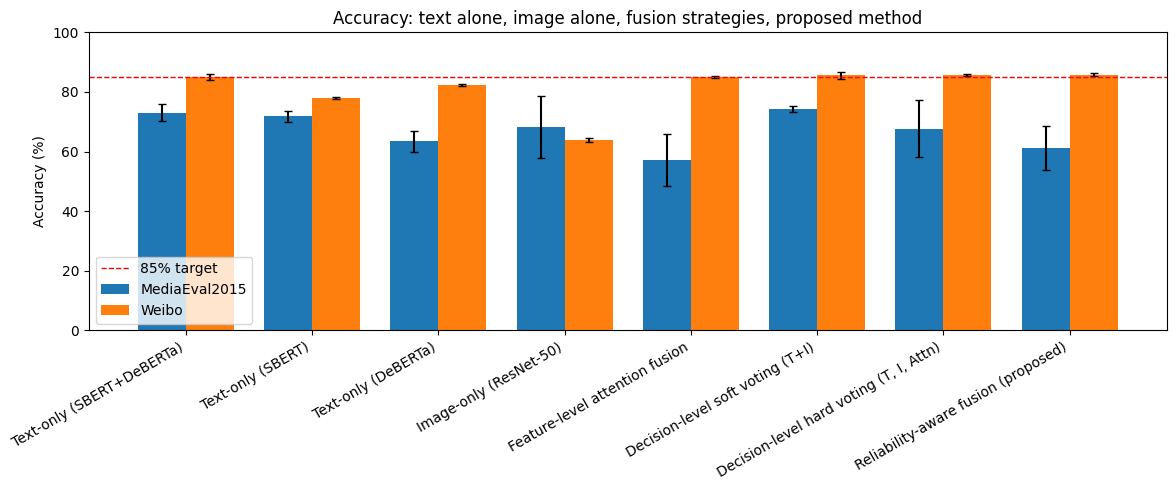


Saved: results_all.csv and results_accuracy.png in /kaggle/working


In [30]:
# CELL 10: RESULTS SECTION (all in one place)
import matplotlib.pyplot as plt
from IPython.display import display

datasets = [d for d in ["MediaEval2015", "Weibo"] if d in ALL_RESULTS]
assert datasets, "Run the dataset cells (8 and 9) first."
methods = list(ALL_RESULTS[datasets[0]].keys())

def stat(name, method, key):
    v = np.array([x[key] for x in ALL_RESULTS[name][method]]) * 100
    return v.mean(), v.std()

fmt = lambda m, s: f"{m:.2f} ± {s:.2f}"

print("=" * 90)
print("RESULTS  |  test set, mean ± std over seeds " + str(CFG["seeds"]) + "  |  fake news = positive class")
print("=" * 90)

# ---- Table 1: unimodal (text alone, image alone) accuracy, both datasets side by side
uni = ["Text-only (SBERT+DeBERTa)", "Text-only (SBERT)", "Text-only (DeBERTa)", "Image-only (ResNet-50)"]
t1 = pd.DataFrame({d: [fmt(*stat(d, m, "Acc")) for m in uni] for d in datasets}, index=uni)
t1.index.name = "Accuracy (%)"
print("\nTable 1. Unimodal accuracy: text alone vs image alone")
display(t1)

# ---- Table 2: all methods, accuracy, both datasets side by side
t2 = pd.DataFrame({d: [fmt(*stat(d, m, "Acc")) for m in methods] for d in datasets}, index=methods)
t2.index.name = "Accuracy (%)"
print("\nTable 2. Accuracy of all methods (unimodal, conventional fusion, proposed, ablations)")
display(t2)

# ---- Table 3: full metrics per dataset
full_rows = []
for d in datasets:
    for m in methods:
        full_rows.append({"Dataset": d, "Method": m.strip(),
                          **{k: fmt(*stat(d, m, k)) for k in ["Acc", "Prec", "Rec", "F1"]}})
t3 = pd.DataFrame(full_rows)
print("\nTable 3. Accuracy / Precision / Recall / F1 (%) per dataset")
display(t3)

# ---- Table 4: target check
prop = "Reliability-aware fusion (proposed)"
best_conv = max(["Feature-level attention fusion", "Decision-level soft voting (T+I)",
                 "Decision-level hard voting (T, I, Attn)"],
                key=lambda m: np.mean([stat(d, m, "Acc")[0] for d in datasets]))
t4 = pd.DataFrame([{
    "Dataset": d,
    "Text-only acc": f"{stat(d, 'Text-only (SBERT+DeBERTa)', 'Acc')[0]:.2f}",
    "Image-only acc": f"{stat(d, 'Image-only (ResNet-50)', 'Acc')[0]:.2f}",
    f"Best conventional ({best_conv})": f"{stat(d, best_conv, 'Acc')[0]:.2f}",
    "Proposed acc": f"{stat(d, prop, 'Acc')[0]:.2f}",
    f"Target >= {CFG['target_acc']*100:.0f}%": "MET" if stat(d, prop, "Acc")[0] >= CFG["target_acc"] * 100 else "NOT MET",
} for d in datasets])
print("\nTable 4. Summary and 85% accuracy target")
display(t4)

# ---- Figure: accuracy of every main method, both datasets
main = [m for m in methods if not m.startswith("  ")]
x, wdt = np.arange(len(main)), 0.38
fig, ax = plt.subplots(figsize=(12, 5))
for i, d in enumerate(datasets):
    vals = [stat(d, m, "Acc")[0] for m in main]
    errs = [stat(d, m, "Acc")[1] for m in main]
    ax.bar(x + (i - (len(datasets) - 1) / 2) * wdt, vals, wdt, yerr=errs, capsize=3, label=d)
ax.axhline(CFG["target_acc"] * 100, color="red", ls="--", lw=1, label="85% target")
ax.set_xticks(x); ax.set_xticklabels(main, rotation=30, ha="right")
ax.set_ylabel("Accuracy (%)"); ax.set_ylim(max(0, min(ax.get_ylim()[0], 50)), 100)
ax.set_title("Accuracy: text alone, image alone, fusion strategies, proposed method")
ax.legend(); plt.tight_layout()
plt.savefig(os.path.join(CFG["work_dir"], "results_accuracy.png"), dpi=200)
plt.show()

# ---- save
t3.to_csv(os.path.join(CFG["work_dir"], "results_all.csv"), index=False)
print("\nSaved: results_all.csv and results_accuracy.png in", CFG["work_dir"])